<a href="https://colab.research.google.com/github/madhavvcs24-arch/AI-LAB/blob/main/Resolution_FOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== FOL Resolution Prover with Visual Tree ===
Syntax:
1. Separate clauses using ;
2. Use | for OR
3. Use ~ for NOT
4. Use Predicate(arguments)
5. Use lowercase variables and uppercase constants

Enter all KB clauses in one line: Human(Socrates); ~Human(x) | Mortal(x)
Enter query to prove: Mortal(Socrates)

=== Minimized Proof (2 Steps) ===
Step 1: [~Mortal(Socrates)] + [Mortal(x_1) | ~Human(x_1)]
        Subst: {'x_1': 'Socrates'} => ~Human(Socrates)
Step 2: [~Human(Socrates)] + [Human(Socrates)]
        Subst: {} => NIL (Empty Clause)

SUCCESS: Empty clause derived! Opening proof graph...


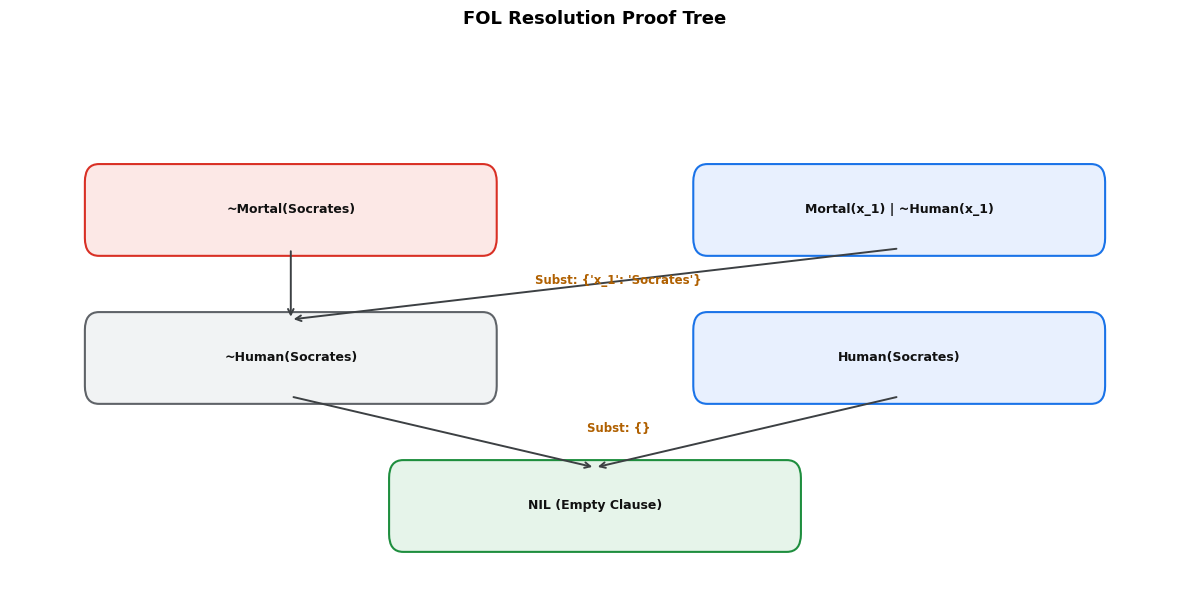

In [ ]:

import re
import heapq
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# --- Parser for User Input ---
def parse_literal(lit_str):
    lit_str = lit_str.strip()
    is_negated = False

    if lit_str.startswith(("~", "!", "¬")):
        is_negated = True
        lit_str = lit_str[1:].strip()

    match = re.match(r"^([A-Za-z][A-Za-z0-9_]*)\(([^()]*)\)$", lit_str)

    if not match:
        raise ValueError(
            f"Invalid literal format: '{lit_str}'. Expected: Predicate(arg1, arg2)"
        )

    pred = match.group(1)
    args = tuple(arg.strip() for arg in match.group(2).split(",") if arg.strip())

    return (is_negated, pred, args)


def parse_clause(clause_str):
    literals = clause_str.split("|")
    return frozenset(
        parse_literal(lit) for lit in literals if lit.strip()
    )


def parse_kb(kb_str):
    raw_clauses = re.split(r"[;&\n]+", kb_str)
    kb = [parse_clause(c) for c in raw_clauses if c.strip()]

    if not kb:
        raise ValueError("Knowledge Base cannot be empty.")

    return kb


# --- FOL Unification & Resolution Engine ---
def is_variable(term):
    return isinstance(term, str) and len(term) > 0 and term[0].islower()


def occur_check(var, term, subst):
    if var == term:
        return True

    if is_variable(term) and term in subst:
        return occur_check(var, subst[term], subst)

    return False


def unify_var(var, x, subst):
    if var in subst:
        return unify(subst[var], x, subst)

    if is_variable(x) and x in subst:
        return unify(var, subst[x], subst)

    if occur_check(var, x, subst):
        return None

    new_subst = subst.copy()
    new_subst[var] = x

    return new_subst


def unify(x, y, subst=None):
    if subst is None:
        subst = {}

    if x == y:
        return subst

    if is_variable(x):
        return unify_var(x, y, subst)

    if is_variable(y):
        return unify_var(y, x, subst)

    if isinstance(x, tuple) and isinstance(y, tuple) and len(x) == len(y):
        for a, b in zip(x, y):
            subst = unify(a, b, subst)

            if subst is None:
                return None

        return subst

    return None


def apply_subst(literal, subst):
    neg, pred, args = literal
    resolved_args = []

    for arg in args:
        while is_variable(arg) and arg in subst:
            arg = subst[arg]

        resolved_args.append(arg)

    return (neg, pred, tuple(resolved_args))


def standardize_variables(clause, counter):
    mapping = {}
    new_literals = set()

    for neg, pred, args in clause:
        new_args = []

        for arg in args:
            if is_variable(arg):
                if arg not in mapping:
                    mapping[arg] = f"{arg}_{counter}"
                    counter += 1

                new_args.append(mapping[arg])
            else:
                new_args.append(arg)

        new_literals.add((neg, pred, tuple(new_args)))

    return frozenset(new_literals), counter


def format_clause(clause):
    if not clause:
        return "NIL (Empty Clause)"

    parts = []

    for neg, pred, args in sorted(clause):
        prefix = "~" if neg else ""
        parts.append(f"{prefix}{pred}({', '.join(args)})")

    return " | ".join(parts)


def resolve(ci, cj):
    resolvents = []

    for li in ci:
        neg_i, pred_i, args_i = li

        for lj in cj:
            neg_j, pred_j, args_j = lj

            if pred_i == pred_j and neg_i != neg_j:
                subst = unify(args_i, args_j, {})

                if subst is not None:
                    new_ci = {
                        apply_subst(l, subst)
                        for l in ci if l != li
                    }

                    new_cj = {
                        apply_subst(l, subst)
                        for l in cj if l != lj
                    }

                    resolvents.append(
                        (frozenset(new_ci | new_cj), subst)
                    )

    return resolvents


# --- Graph Visualizer ---
def draw_proof_graph(proof_steps, negated_query):
    num_steps = len(proof_steps)

    fig, ax = plt.subplots(figsize=(12, max(6, num_steps * 1.6)))

    ax.set_xlim(0, 10)
    ax.set_ylim(-0.5, num_steps + 1.2)
    ax.axis("off")

    def draw_node(x, y, text, fc="#E8F0FE", ec="#1A73E8"):
        width = max(3.4, len(text) * 0.11)

        box = patches.FancyBboxPatch(
            (x - width / 2, y - 0.25),
            width, 0.5,
            boxstyle="round,pad=0.06,rounding_size=0.12",
            facecolor=fc,
            edgecolor=ec,
            linewidth=1.5
        )

        ax.add_patch(box)

        ax.text(
            x, y, text,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color="#111111"
        )

    coords = {}

    for idx, (c1, c2, subst, res) in enumerate(proof_steps):
        y_parent = num_steps - idx
        y_child = y_parent - 1

        if c1 not in coords:
            fc1 = "#FCE8E6" if c1 == negated_query else "#E8F0FE"
            ec1 = "#D93025" if c1 == negated_query else "#1A73E8"

            coords[c1] = (2.4, y_parent)

            draw_node(
                2.4, y_parent, format_clause(c1),
                fc=fc1, ec=ec1
            )

        if c2 not in coords:
            coords[c2] = (7.6, y_parent)

            draw_node(
                7.6, y_parent, format_clause(c2),
                fc="#E8F0FE", ec="#1A73E8"
            )

        x_child = 5.0 if len(res) == 0 else 2.4

        fc_res = "#E6F4EA" if len(res) == 0 else "#F1F3F4"
        ec_res = "#1E8E3E" if len(res) == 0 else "#5F6368"

        coords[res] = (x_child, y_child)

        draw_node(
            x_child, y_child, format_clause(res),
            fc=fc_res, ec=ec_res
        )

        for parent in (c1, c2):
            px, py = coords[parent]

            ax.annotate(
                "",
                xy=(x_child, y_child + 0.26),
                xytext=(px, py - 0.26),
                arrowprops=dict(
                    arrowstyle="->",
                    lw=1.4,
                    color="#3C4043"
                )
            )

        subst_str = str(subst) if subst else "{}"

        ax.text(
            5.2,
            (y_parent + y_child) / 2,
            f"Subst: {subst_str}",
            fontsize=8.5,
            color="#B06000",
            fontweight="bold",
            ha="center"
        )

    plt.title("FOL Resolution Proof Tree", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


# --- Extract and Display Proof ---
def extract_and_show_proof(empty_clause, parents, negated_query):
    proof_steps = []
    visited = set()

    def trace(clause):
        if clause in visited or clause not in parents:
            return

        visited.add(clause)

        c1, c2, subst = parents[clause]

        trace(c1)
        trace(c2)

        proof_steps.append((c1, c2, subst, clause))

    trace(empty_clause)

    print(f"\n=== Minimized Proof ({len(proof_steps)} Steps) ===")

    for step_num, (c1, c2, subst, res) in enumerate(proof_steps, 1):
        print(
            f"Step {step_num}: [{format_clause(c1)}] + "
            f"[{format_clause(c2)}]"
        )

        print(
            f"        Subst: {subst} => {format_clause(res)}"
        )

    print("\nSUCCESS: Empty clause derived! Opening proof graph...")

    draw_proof_graph(proof_steps, negated_query)


# --- FOL Resolution Algorithm ---
def fol_resolution_minimized(kb, query):
    counter = 1
    kb_clauses = []
    seen = set()

    for c in kb:
        std_c, counter = standardize_variables(c, counter)

        if std_c not in seen:
            kb_clauses.append(std_c)
            seen.add(std_c)

    q_neg, q_pred, q_args = query

    negated_query = frozenset({
        (not q_neg, q_pred, q_args)
    })

    std_q, counter = standardize_variables(negated_query, counter)

    seen.add(std_q)

    tie_breaker = 0

    sos_queue = [(len(std_q), tie_breaker, std_q)]
    sos_list = [std_q]

    parents = {}

    while sos_queue:
        _, _, current = heapq.heappop(sos_queue)

        candidates = kb_clauses + sos_list

        for other in candidates:
            if current == other:
                continue

            for resolvent, subst in resolve(current, other):

                if resolvent not in seen:
                    seen.add(resolvent)

                    parents[resolvent] = (
                        current, other, subst
                    )

                    if len(resolvent) == 0:
                        extract_and_show_proof(
                            resolvent, parents, std_q
                        )
                        return True

                    tie_breaker += 1

                    sos_list.append(resolvent)

                    heapq.heappush(
                        sos_queue,
                        (len(resolvent), tie_breaker, resolvent)
                    )

    print("\nFAILED: Empty clause cannot be derived.")
    print("Query CANNOT be proved.")

    return False


# --- Interactive Main Loop ---
if __name__ == "__main__":

    print("=== FOL Resolution Prover with Visual Tree ===")

    print("Syntax:")
    print("1. Separate clauses using ;")
    print("2. Use | for OR")
    print("3. Use ~ for NOT")
    print("4. Use Predicate(arguments)")
    print("5. Use lowercase variables and uppercase constants\n")

    try:
        raw_kb = input("Enter all KB clauses in one line: ")

        kb = parse_kb(raw_kb)

        raw_query = input("Enter query to prove: ")

        query = parse_literal(raw_query)

        fol_resolution_minimized(kb, query)

    except Exception as e:
        print(f"\nInput Error: {e}")
